
### Quantitative Research · BTC / ETH · 3-minute bars
  Cross-Asset Return Dynamics & Predictability
  Leakage-aware analysis of 2.37 million market bars, temporal regimes, and next-bar return benchmarks.

  >/pandas, scikit-learn, LightGBM, CatBoost

Returns are heavy-tailed, BTC and ETH are strongly co-moving, and univariate next-bar associations are weak or non-monotonic. Models are benchmarked using temporal folds and a final chronological holdout; no result by itself establishes a tradable edge.



## Table of contents

1. [Problem Statement & Environment Setup](#chapter-1)
2. [Universal Data Ingestion & Data Auditing](#chapter-2)
3. [Data Cleaning & Preprocessing Pipeline](#chapter-3)
4. [In-Depth Exploratory Data Analysis](#chapter-4)
5. [Publication-Grade 2D & 3D Visualizations](#chapter-5)
6. [Validation Strategy & Model Benchmarking](#chapter-6)
7. [Hyperparameter Optimization & Explainable AI](#chapter-7)
8. [Strategic Conclusions & Future Recommendations](#chapter-8)


<a id="chapter-1"></a>
# 1. Problem Statement & Environment Setup

This research compares BTCUSDT and ETHUSDT 3-minute bars. The response under study is the **exploratory** next-bar log return `log(close[t+1] / close[t])`; only information available at bar t may be used as a predictor. Data are descriptive market records, not a trading recommendation.

In [ ]:
import json
import os
import sys
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd()
if not (ROOT / 'data' / 'processed').exists():
    ROOT = ROOT.parent
os.environ['MPLCONFIGDIR'] = str(ROOT / 'reports' / '.mplconfig-cache')
sys.path.insert(0, str(ROOT / 'src'))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import HTML, Image, display
from config import FEATURES, FIGURES_DIR, REPORTS_DIR, TARGET_NAME
print('Project root:', ROOT)
print('Target:', TARGET_NAME)
print('Predictors:', len(FEATURES))

Project root: D:\File VS Code\kaw
Target: future_log_return_3m
Predictors: 15


<a id="chapter-2"></a>
# 2. Universal Data Ingestion & Data Auditing

Both inputs are final Parquet datasets. The audit checks dimensions, missingness, exact duplicates, constant fields, timestamp range, and representative source rows without modifying the source files.

In [9]:
from data_loader import load_all_market_data
frames = load_all_market_data()
audit_rows = []
for symbol, frame in frames.items():
    audit_rows.append({
        'asset': symbol,
        'rows': len(frame),
        'columns': frame.shape[1],
        'memory_bytes': int(frame.memory_usage(index=True, deep=True).sum()),
        'missing_cells': int(frame.isna().sum().sum()),
        'duplicate_rows': int(frame.duplicated().sum()),
        'constant_columns': [c for c in frame if frame[c].nunique(dropna=False) <= 1],
        'start_utc': frame['dt'].min(),
        'end_utc': frame['dt'].max(),
    })
display(pd.DataFrame(audit_rows))
for symbol, frame in frames.items():
    print(f'First five rows — {symbol}')
    display(frame[['dt','open','high','low','close','volume','trades','buy_ratio']].head())

,asset,rows,columns,memory_bytes,missing_cells,duplicate_rows,constant_columns,start_utc,end_utc
0,BTCUSDT,1206229,15,153191215,0,0,[symbol],2019-09-08 17:57:00+00:00,2026-07-26 17:21:00+00:00
1,ETHUSDT,1168035,15,148340577,0,0,[symbol],2019-11-27 07:45:00+00:00,2026-07-26 17:27:00+00:00


First five rows — BTCUSDT


,dt,open,high,low,close,volume,trades,buy_ratio
0,2019-09-08 17:57:00+00:00,10000.0,10000.0,10000.0,10000.0,0.002,2,0.5
1,2019-09-08 18:00:00+00:00,10000.0,10000.0,10000.0,10000.0,0.000,0,0.0
2,2019-09-08 18:03:00+00:00,10000.0,10000.0,10000.0,10000.0,0.000,0,0.0
3,2019-09-08 18:06:00+00:00,10000.0,10000.0,10000.0,10000.0,0.000,0,0.0
4,2019-09-08 18:09:00+00:00,10000.0,10000.0,10000.0,10000.0,0.000,0,0.0


First five rows — ETHUSDT


,dt,open,high,low,close,volume,trades,buy_ratio
0,2019-11-27 07:45:00+00:00,146.0,146.0,146.0,146.0,0.01,1,0.0
1,2019-11-27 07:48:00+00:00,146.0,146.0,146.0,146.0,0.00,0,0.0
2,2019-11-27 07:51:00+00:00,146.0,146.0,146.0,146.0,0.00,0,0.0
3,2019-11-27 07:54:00+00:00,146.0,146.0,146.0,146.0,0.00,0,0.0
4,2019-11-27 07:57:00+00:00,146.0,146.0,146.0,146.0,0.00,0,0.0


<a id="chapter-3"></a>
# 3. Data Cleaning & Preprocessing Pipeline

The confirmed status is FINAL, so no destructive cleaning or source rewrite was performed. Features are engineered independently per asset and in timestamp order. The target is masked wherever the next observation is not exactly one 3-minute bar later. Missing lag values are imputed only inside each fitted cross-validation pipeline.

In [10]:
from preprocessing import build_panel
panel = build_panel(frames)
print('Panel shape:', panel.shape)
print('Target availability:', float(panel[TARGET_NAME].notna().mean()))
display(panel[['dt','asset',*FEATURES,TARGET_NAME]].head(8))
print('Feature columns are all measured at t or earlier; target uses close[t+1].')

Panel shape: (2374264, 18)
Target availability: 0.999999157633692


,dt,asset,current_log_return,bar_return,return_lag_1,return_lag_3,return_lag_5,realized_volatility_20,range_log,log_volume,log_trades,buy_ratio,hour_sin,hour_cos,weekday_sin,weekday_cos,asset_code,future_log_return_3m
0,2019-09-08 17:57:00+00:00,BTCUSDT,0.0,NaN,NaN,NaN,NaN,NaN,0.0,0.001998,1.098612,0.5,-0.965926,-2.588190e-01,-0.781831,0.62349,0,0.0
1,2019-09-08 18:00:00+00:00,BTCUSDT,0.0,0.0,NaN,NaN,NaN,NaN,0.0,0.000000,0.000000,0.0,-1.000000,-1.836970e-16,-0.781831,0.62349,0,0.0
2,2019-09-08 18:03:00+00:00,BTCUSDT,0.0,0.0,0.0,NaN,NaN,NaN,0.0,0.000000,0.000000,0.0,-1.000000,-1.836970e-16,-0.781831,0.62349,0,0.0
3,2019-09-08 18:06:00+00:00,BTCUSDT,0.0,0.0,0.0,NaN,NaN,NaN,0.0,0.000000,0.000000,0.0,-1.000000,-1.836970e-16,-0.781831,0.62349,0,0.0
4,2019-09-08 18:09:00+00:00,BTCUSDT,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.000000,0.000000,0.0,-1.000000,-1.836970e-16,-0.781831,0.62349,0,0.0
5,2019-09-08 18:12:00+00:00,BTCUSDT,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.000000,0.000000,0.0,-1.000000,-1.836970e-16,-0.781831,0.62349,0,0.0
6,2019-09-08 18:15:00+00:00,BTCUSDT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,-1.000000,-1.836970e-16,-0.781831,0.62349,0,0.0
7,2019-09-08 18:18:00+00:00,BTCUSDT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,-1.000000,-1.836970e-16,-0.781831,0.62349,0,0.0


Feature columns are all measured at t or earlier; target uses close[t+1].


<a id="chapter-4"></a>
# 4. In-Depth Exploratory Data Analysis (EDA)

The tests below are accompanied by effect sizes and explicitly treated as descriptive because serial dependence violates independent-observation assumptions of classical p-values.

In [11]:
eda = json.loads((REPORTS_DIR / 'eda_summary.json').read_text(encoding='utf-8'))
return_rows = []
for asset_name, details in eda['dataset_profile'].items():
    row = {'asset': asset_name, **details['return_summary']}
    row.update({
        'hour_kruskal_p': details['seasonality']['hour_p_value'],
        'hour_epsilon2': details['seasonality']['hour_epsilon_squared'],
        'peak_hour_utc': details['seasonality']['highest_median_hour_utc'],
        'weekday_kruskal_p': details['seasonality']['weekday_p_value'],
        'weekday_epsilon2': details['seasonality']['weekday_epsilon_squared'],
    })
    return_rows.append(row)
display(pd.DataFrame(return_rows))
display(pd.DataFrame(eda['cross_asset_returns'], index=['value']).T)
display(pd.DataFrame(eda['mutual_information_nats']))

,asset,n,mean,std,skew,excess_kurtosis,q01,median,q99,hour_kruskal_p,hour_epsilon2,peak_hour_utc,weekday_kruskal_p,weekday_epsilon2
0,BTCUSDT,1206228,0.000002,0.001564,-1.119775,178.251064,-0.004196,0.0,0.00423,<1e-300,0.059047,14,2.593137e-55,0.105161
1,ETHUSDT,1168034,0.000002,0.002031,-1.433392,249.143081,-0.005469,0.0,0.00552,<1e-300,0.053723,14,1.665239e-35,0.070353


,value
aligned_n,1168032
pearson_r,0.824527
pearson_p_value,<1e-300
spearman_rho,0.813414
spearman_p_value,<1e-300
btc_t_to_eth_t_plus_1_r,-0.01519
btc_t_to_eth_t_plus_1_p_value,0.0
eth_t_to_btc_t_plus_1_r,-0.013049
eth_t_to_btc_t_plus_1_p_value,0.0


,BTCUSDT,ETHUSDT
current_log_return,0.059900,0.053352
range_log,0.132729,0.125545
log_volume,0.074165,0.066263
log_trades,0.063256,0.051799
buy_ratio,0.003199,0.010449
flow_imbalance,0.003189,0.010449


<a id="chapter-5"></a>
# 5. Publication-Grade 2D & 3D Visualizations

All static charts are exported at 300 DPI. The 3D chart is self-contained and interactive; chart captions state the intended takeaway.

return_distribution.png


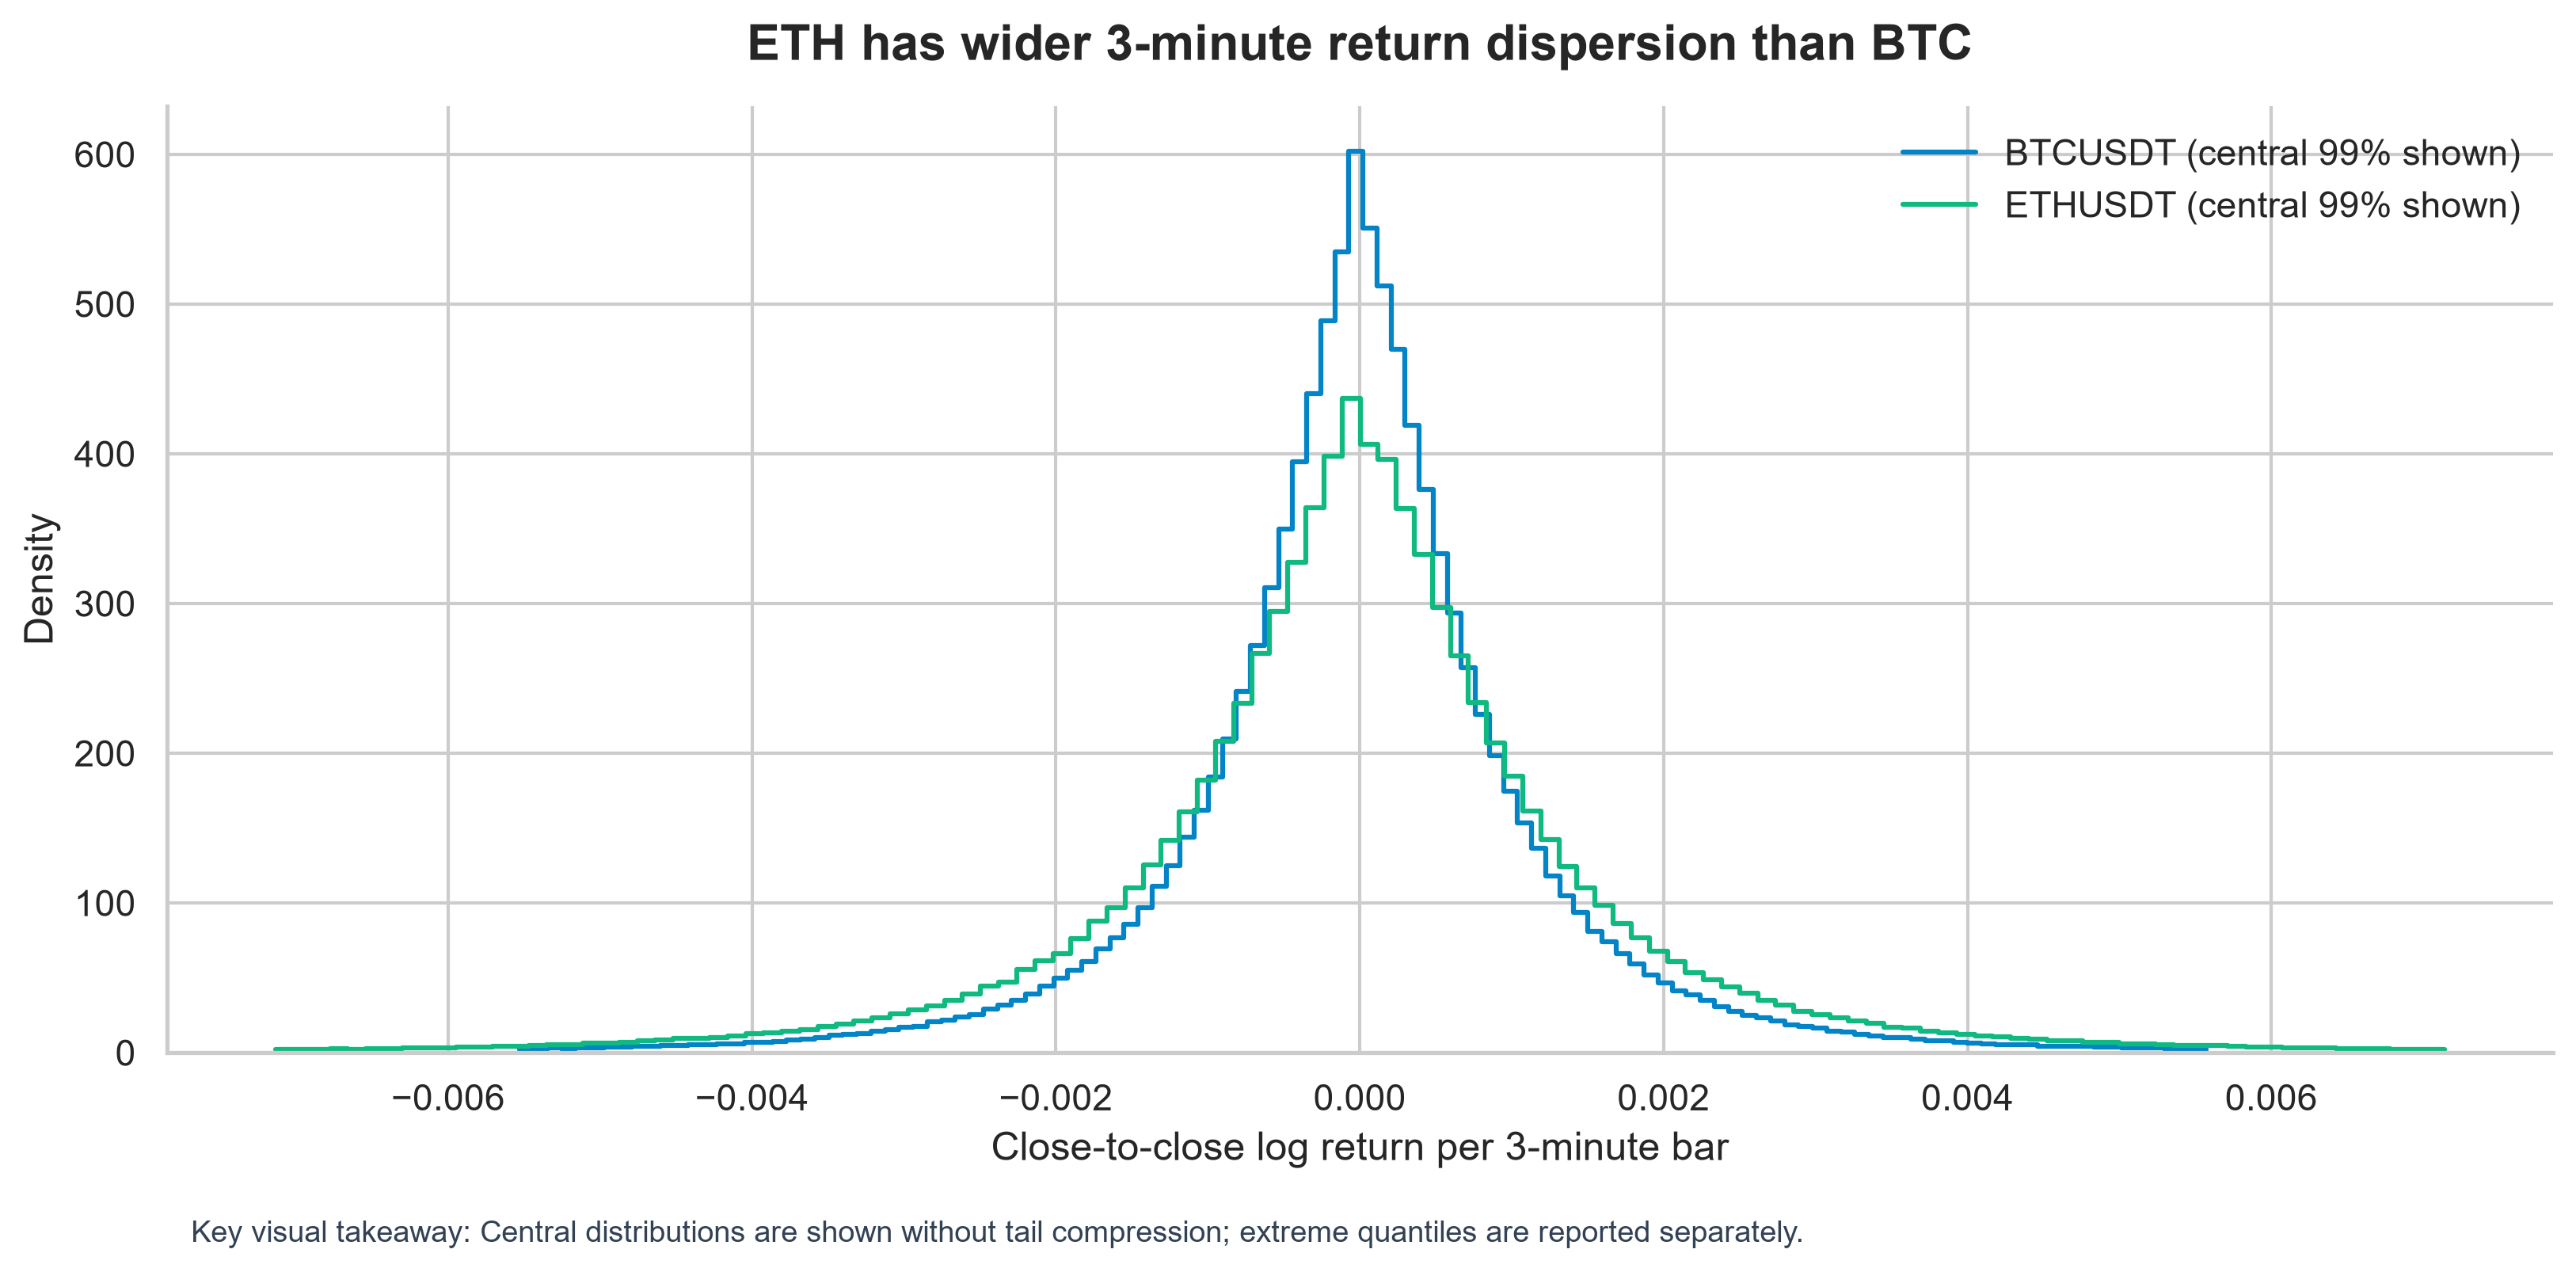

temporal_volatility_heatmap.png


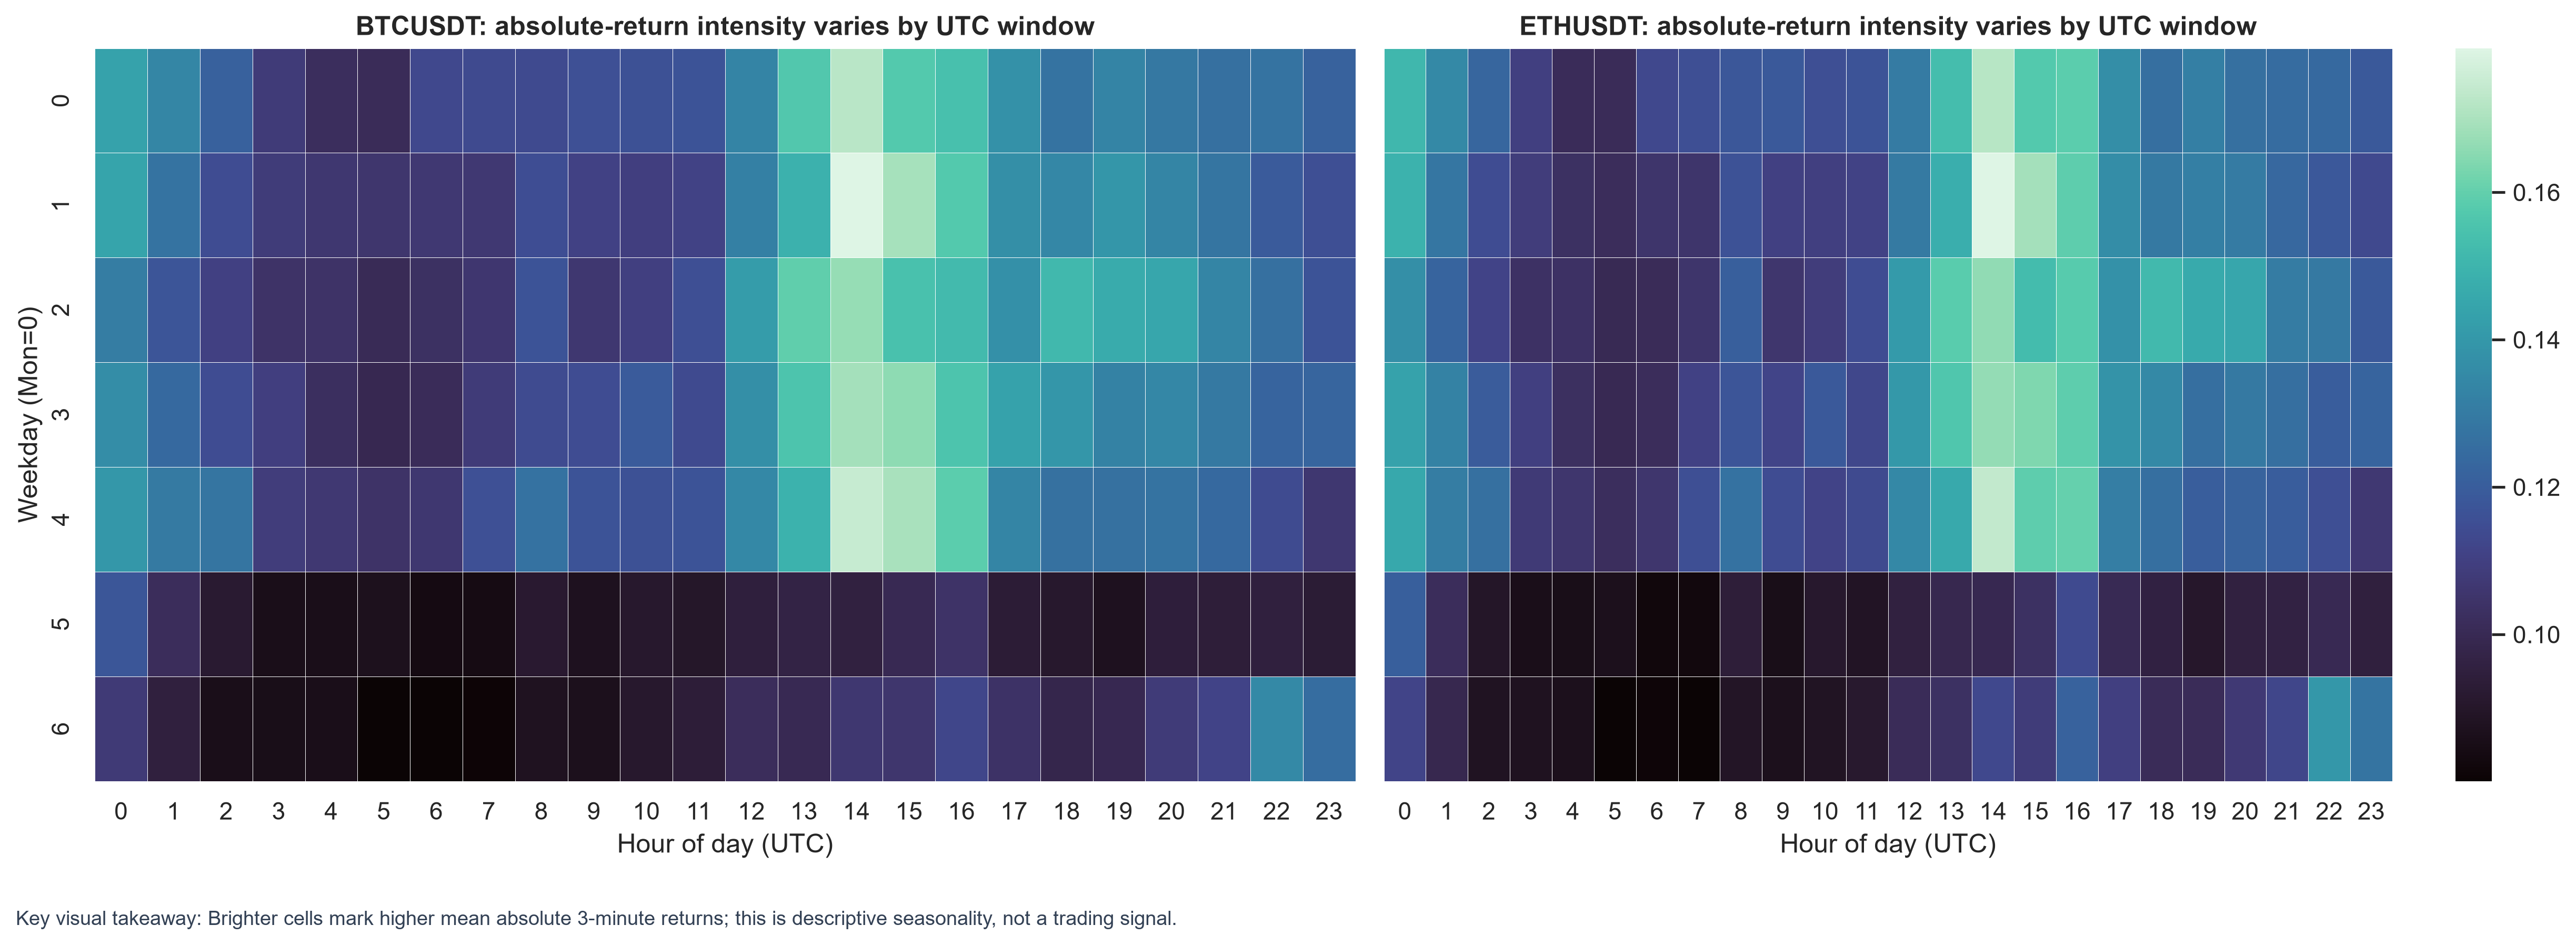

rolling_30d_cross_asset_correlation.png


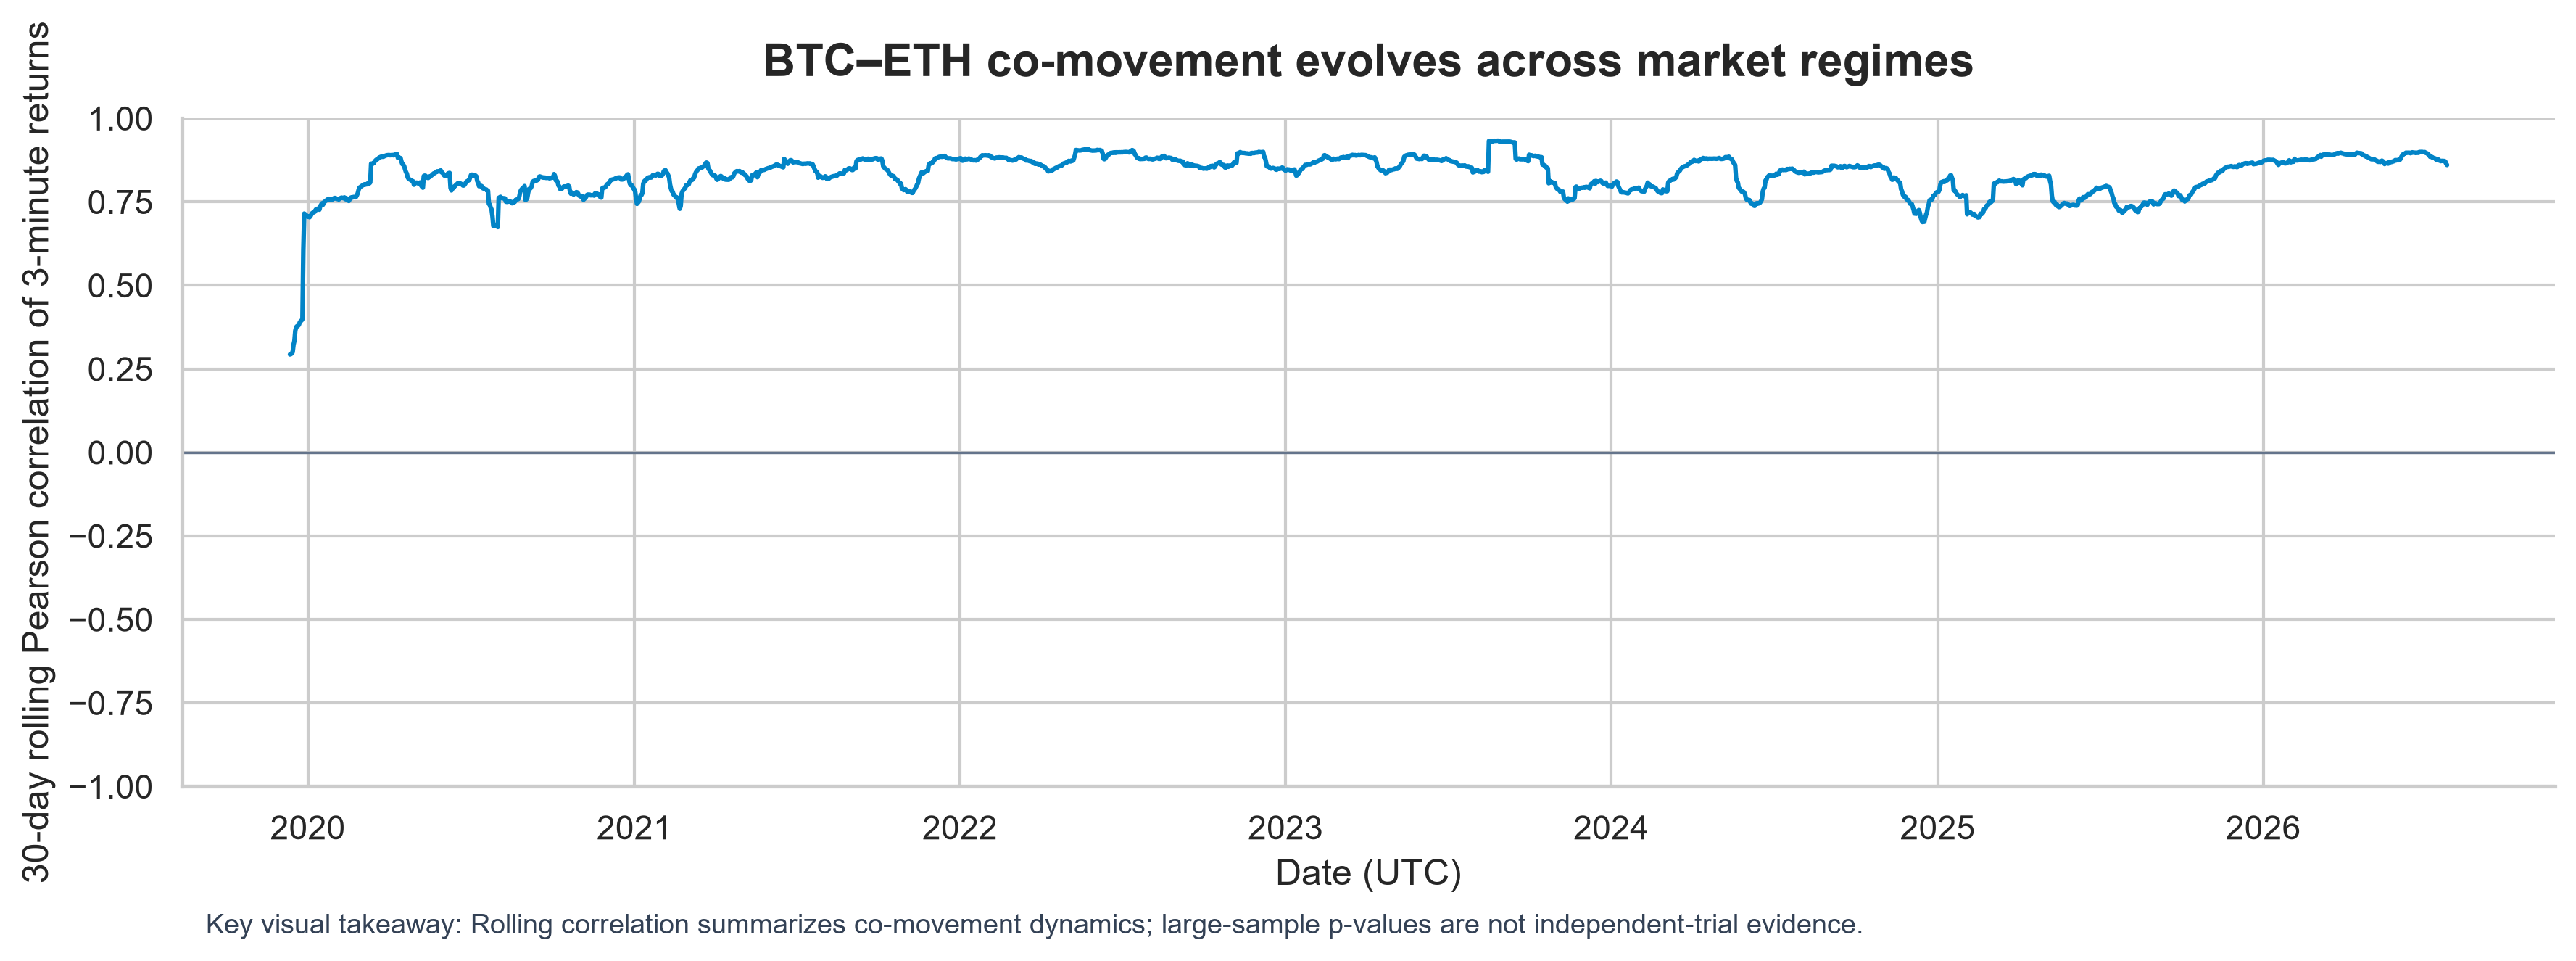

mutual_information_future_return.png


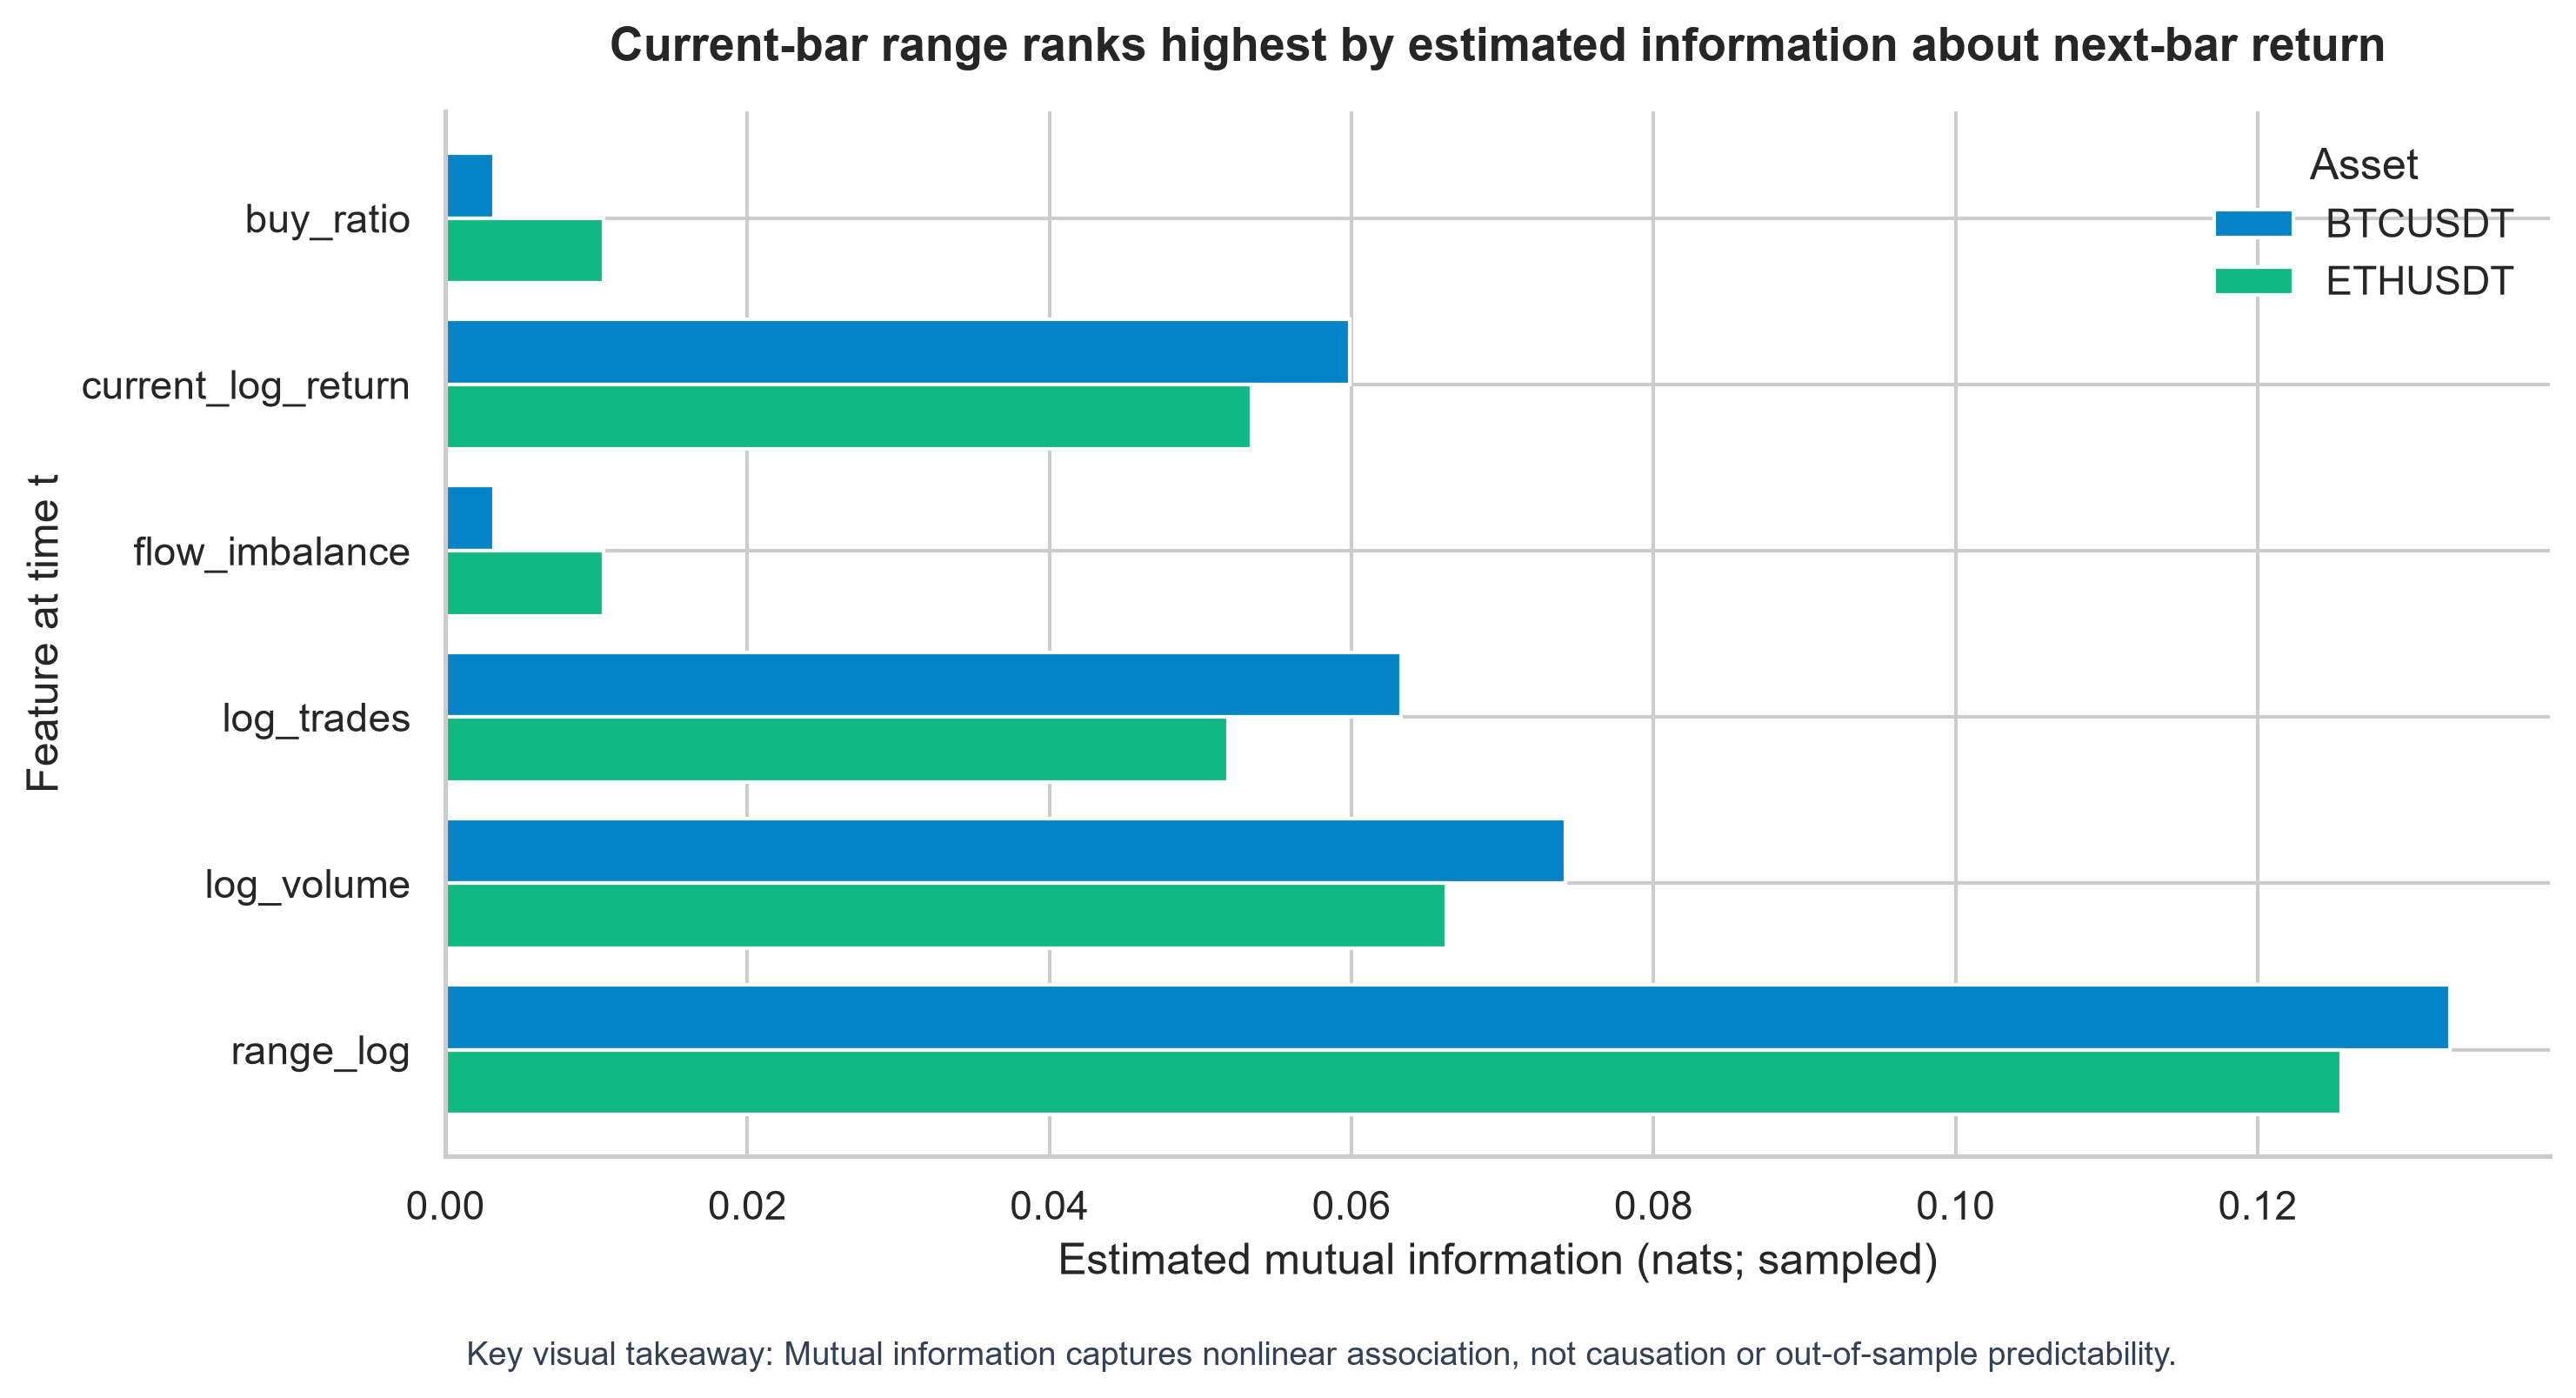

Key visual takeaway: broad scatter is expected; it does not demonstrate profitability.


In [12]:
for figure_name in [
    'return_distribution.png',
    'temporal_volatility_heatmap.png',
    'rolling_30d_cross_asset_correlation.png',
    'mutual_information_future_return.png',
]:
    print(figure_name)
    display(Image(filename=str(FIGURES_DIR / figure_name)))
interactive_sample = panel.dropna(subset=[TARGET_NAME]).sample(
    n=min(6000, int(panel[TARGET_NAME].notna().sum())), random_state=42
)
interactive = px.scatter_3d(
    interactive_sample, x='range_log', y='log_volume', z=TARGET_NAME,
    color='asset', opacity=0.55,
    title='Current-bar range and activity versus next 3-minute return',
    hover_data=['dt','buy_ratio'],
)
interactive.update_layout(scene={'camera': {'eye': {'x': 1.55, 'y': 1.55, 'z': 1.15}}})
display(HTML(interactive.to_html(full_html=False, include_plotlyjs=True)))
print('Key visual takeaway: broad scatter is expected; it does not demonstrate profitability.')

<a id="chapter-6"></a>
# 6. Validation Strategy & Model Benchmarking

Tuning uses an earlier temporal window; five expanding-window folds produce OOF scores after that window. One timestamp is purged at every boundary, assets at a shared timestamp remain together, and the final 10% of unique timestamps is held out chronologically. Optuna uses a deterministic one-in-ten timestamp sample for search speed; OOF and holdout evaluation use the full row set.

In [13]:
metrics = json.loads((REPORTS_DIR / 'metrics_summary.json').read_text(encoding='utf-8'))
leaderboard = pd.DataFrame([
    {
        'model': row['model'],
        'OOF MAE': row['oof']['mae'],
        'OOF MAE skill vs zero': row['oof_mae_skill_vs_zero'],
        'OOF RMSE': row['oof']['rmse'],
        'OOF rank IC': row['oof']['spearman_ic'],
        'Holdout MAE': row['holdout']['mae'],
        'Holdout MAE skill vs zero': row['holdout_mae_skill_vs_zero'],
        'Holdout RMSE': row['holdout']['rmse'],
        'Holdout rank IC': row['holdout']['spearman_ic'],
    }
    for row in metrics['leaderboard']
]).sort_values('OOF MAE')
display(leaderboard)
print('Best by OOF MAE:', metrics['experiment']['selected_model_by_oof_mae'])
print('Zero-return baseline:', metrics['experiment']['zero_return_baseline'])
print('Split metadata:', metrics['experiment'])

,model,OOF MAE,OOF MAE skill vs zero,OOF RMSE,OOF rank IC,Holdout MAE,Holdout MAE skill vs zero,Holdout RMSE,Holdout rank IC
1,HistGradientBoostingRegressor,0.000919,0.000942,0.001454,0.033866,0.000826,0.001831,0.001331,0.049364
2,LGBMRegressor,0.000919,0.000921,0.001455,0.034278,0.000825,0.002381,0.001333,0.050346
3,CatBoostRegressor,0.000919,0.000843,0.001454,0.032916,0.000826,0.001555,0.001331,0.049679
0,Ridge,0.000919,0.000403,0.001454,0.023036,0.000826,0.001160,0.001332,0.038518


Best by OOF MAE: HistGradientBoostingRegressor
Zero-return baseline: {'oof': {'mae': 0.0009196308004521614, 'rmse': 0.0014537299782988228}, 'holdout': {'mae': 0.0008274423109532349, 'rmse': 0.0013311303859711483}}
Split metadata: {'target': 'future_log_return_3m', 'target_definition': 'log(close[t+1] / close[t])', 'feature_availability': 'bar t and earlier only', 'feature_names': ['current_log_return', 'bar_return', 'return_lag_1', 'return_lag_3', 'return_lag_5', 'realized_volatility_20', 'range_log', 'log_volume', 'log_trades', 'buy_ratio', 'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'asset_code'], 'models': ['Ridge', 'HistGradientBoostingRegressor', 'LGBMRegressor', 'CatBoostRegressor'], 'selected_model_by_oof_mae': 'HistGradientBoostingRegressor', 'optuna_trials_per_model': 2, 'optuna_training_timestamp_stride': 10, 'outer_time_series_splits': 5, 'time_gap_bars': 1, 'holdout_fraction_unique_timestamps': 0.1, 'tuning_fraction_of_development': {'train_end': 0.6, 'validation_

In [ ]:
best = metrics['experiment']['selected_model_by_oof_mae']
best_row = next(row for row in metrics['leaderboard'] if row['model'] == best)
callout_style = (
    "<div style='background-color:#F8FAFC;border-left:5px solid #0284C7;"
    "padding:14px 18px;border-radius:6px;margin:12px 0;color:#0F172A;'>"
    "<strong>Note:</strong> "
)
display(HTML(f"{callout_style}OOF MAE for {best}: {best_row['oof']['mae']:.7g}; "
f"chronological holdout MAE: {best_row['holdout']['mae']:.7g}. "
f"Treat the holdout as one final estimate, not a tuning target.</div>"))

<a id="chapter-7"></a>
# 7. Hyperparameter Optimization & Explainable AI

Optuna searches a bounded set of parameters on a forward validation window. The selected model is chosen by OOF MAE, then inspected on the separate chronological holdout. SHAP is model-agnostic permutation attribution on a fixed sample; attribution is not causation.

residual_diagnostics.png


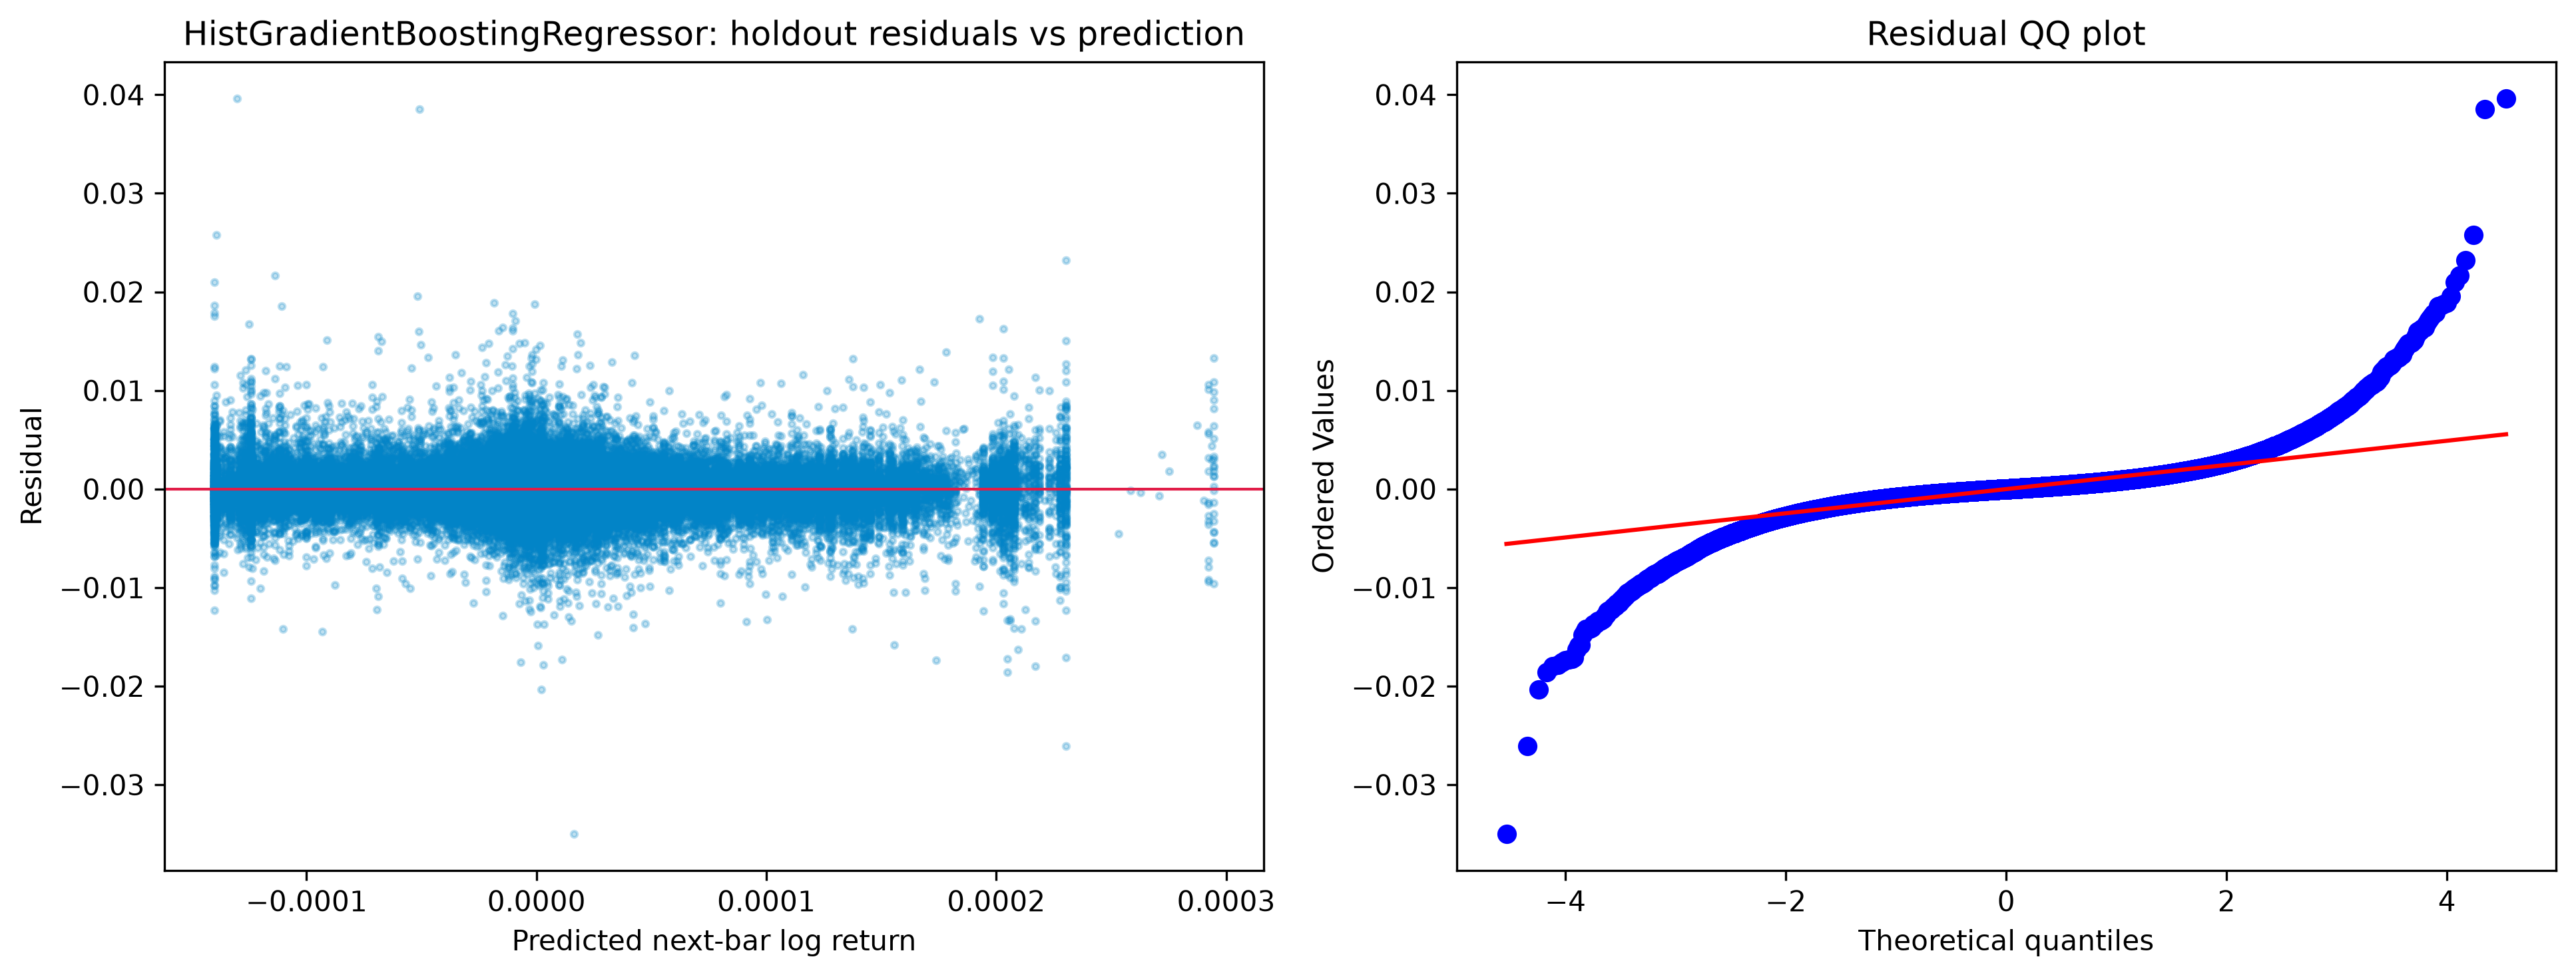

shap_summary.png


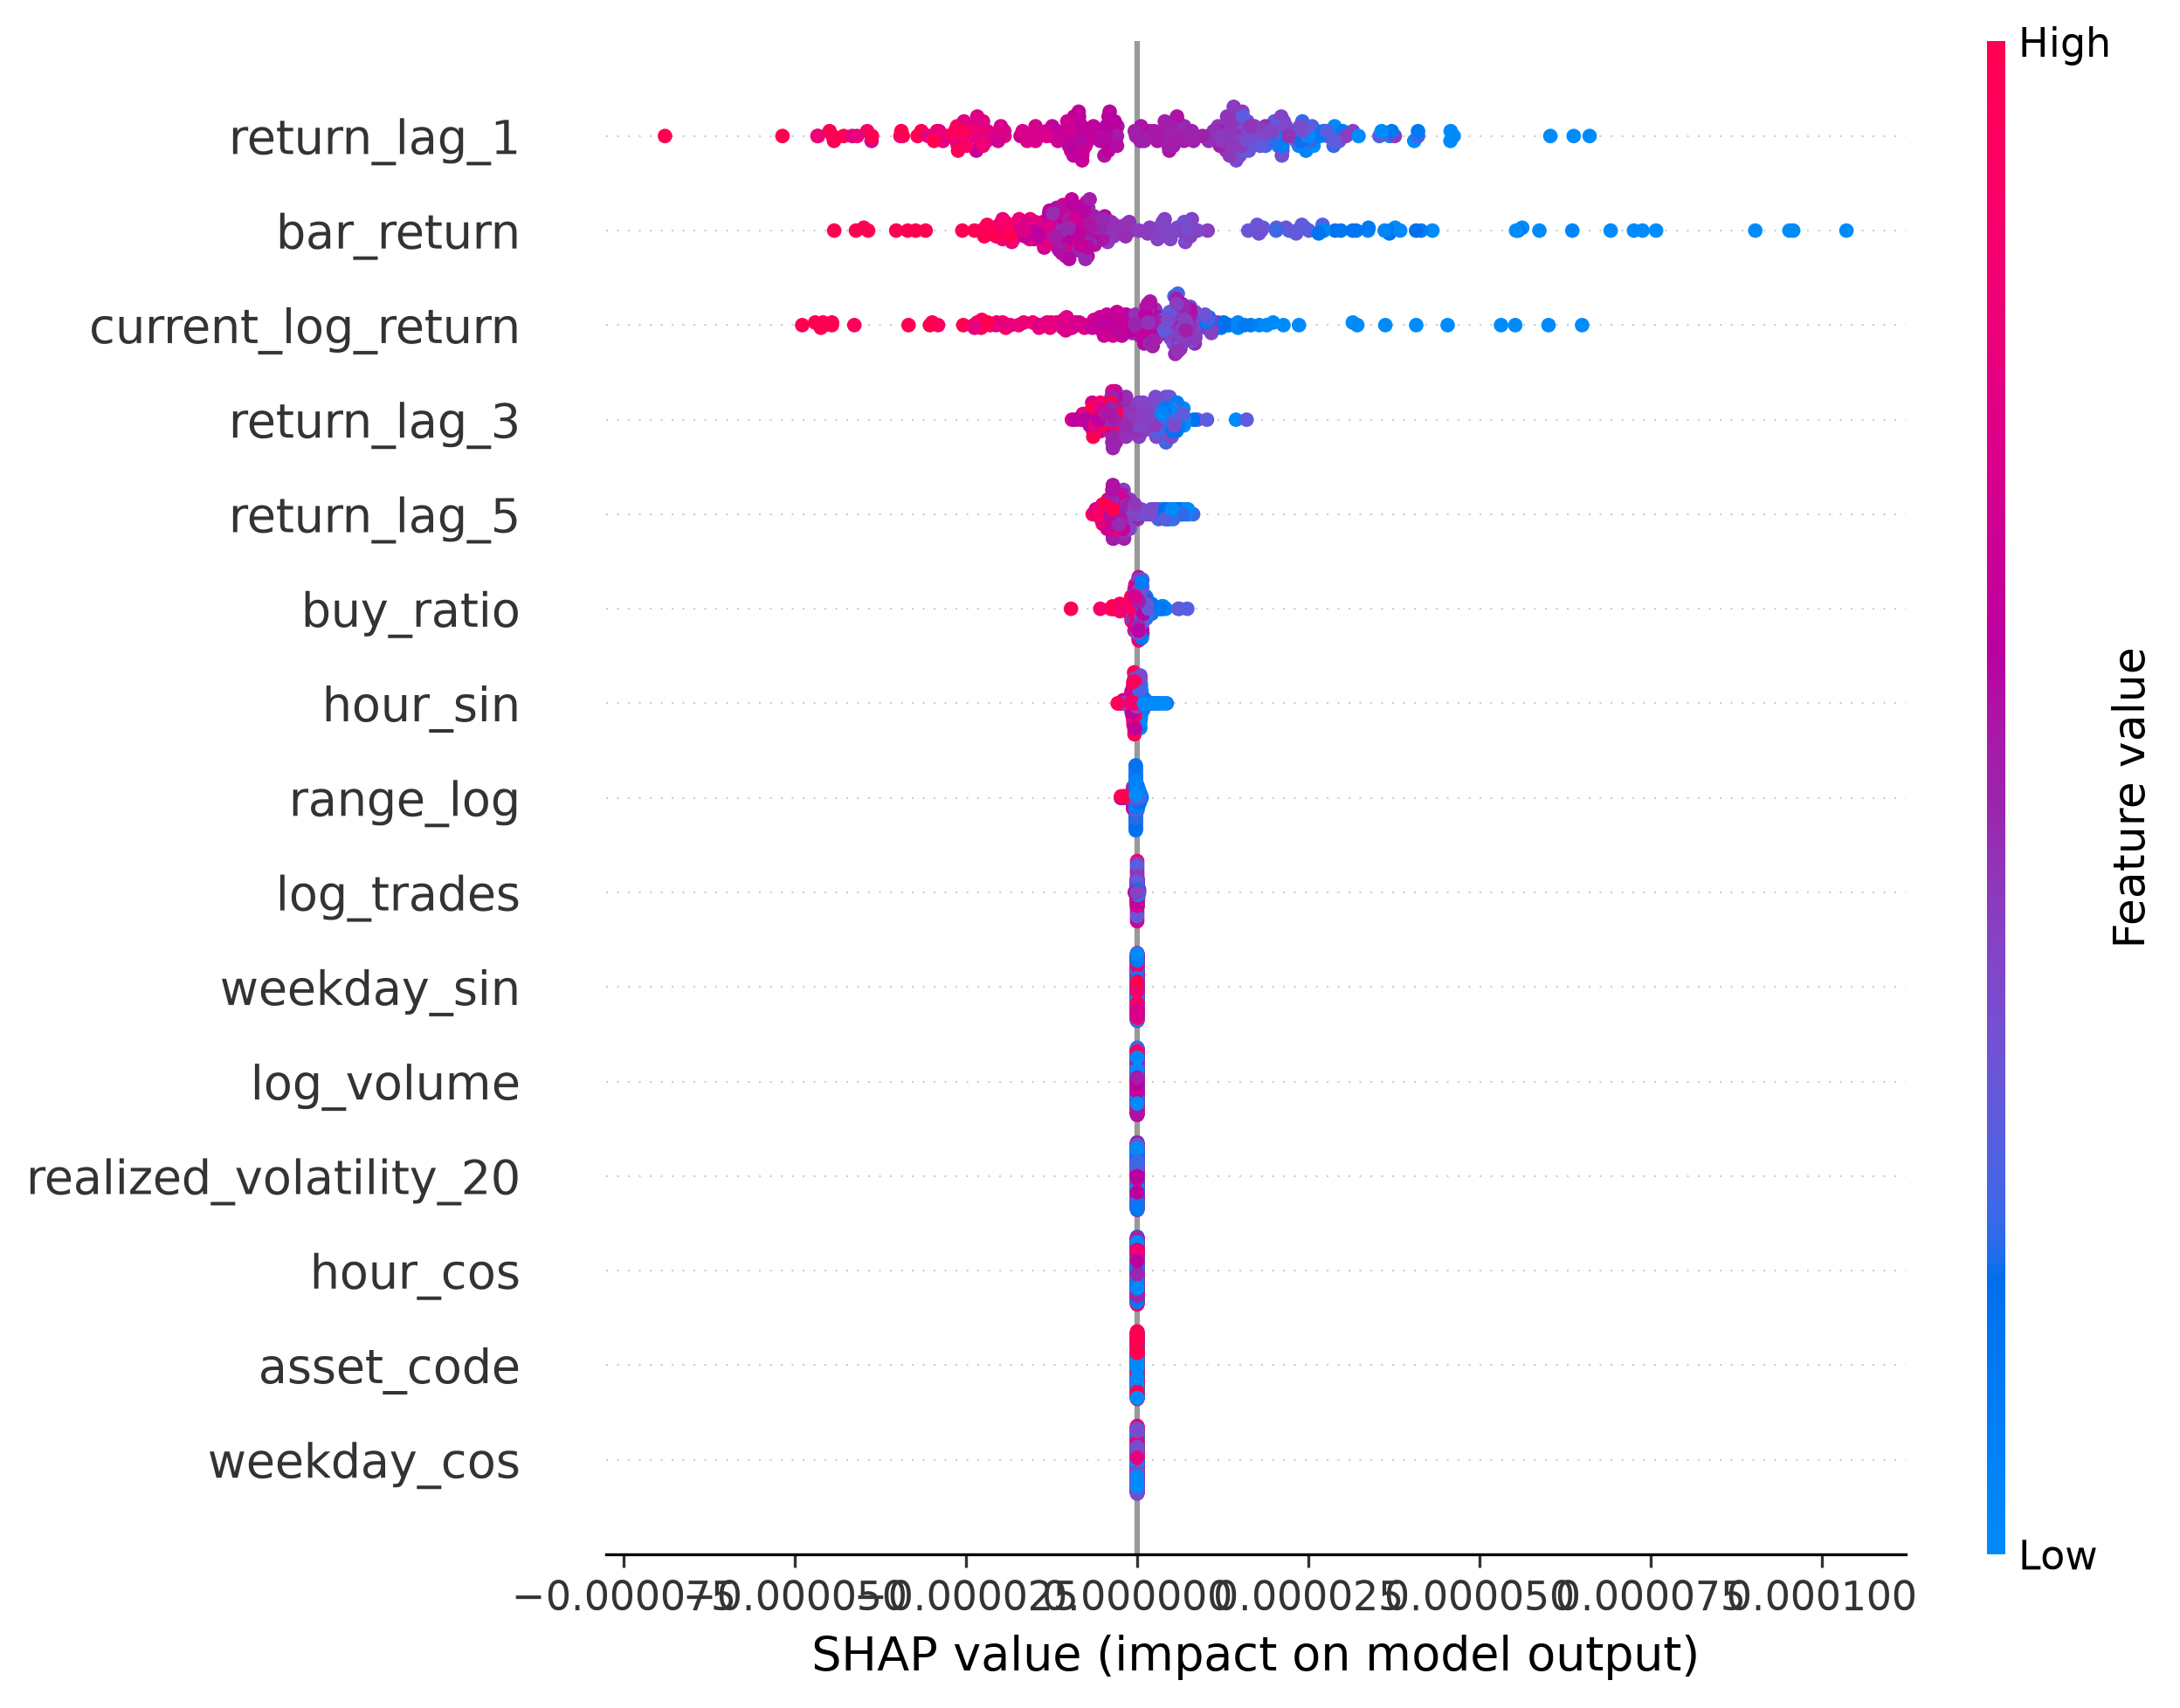

shap_importance_bar.png


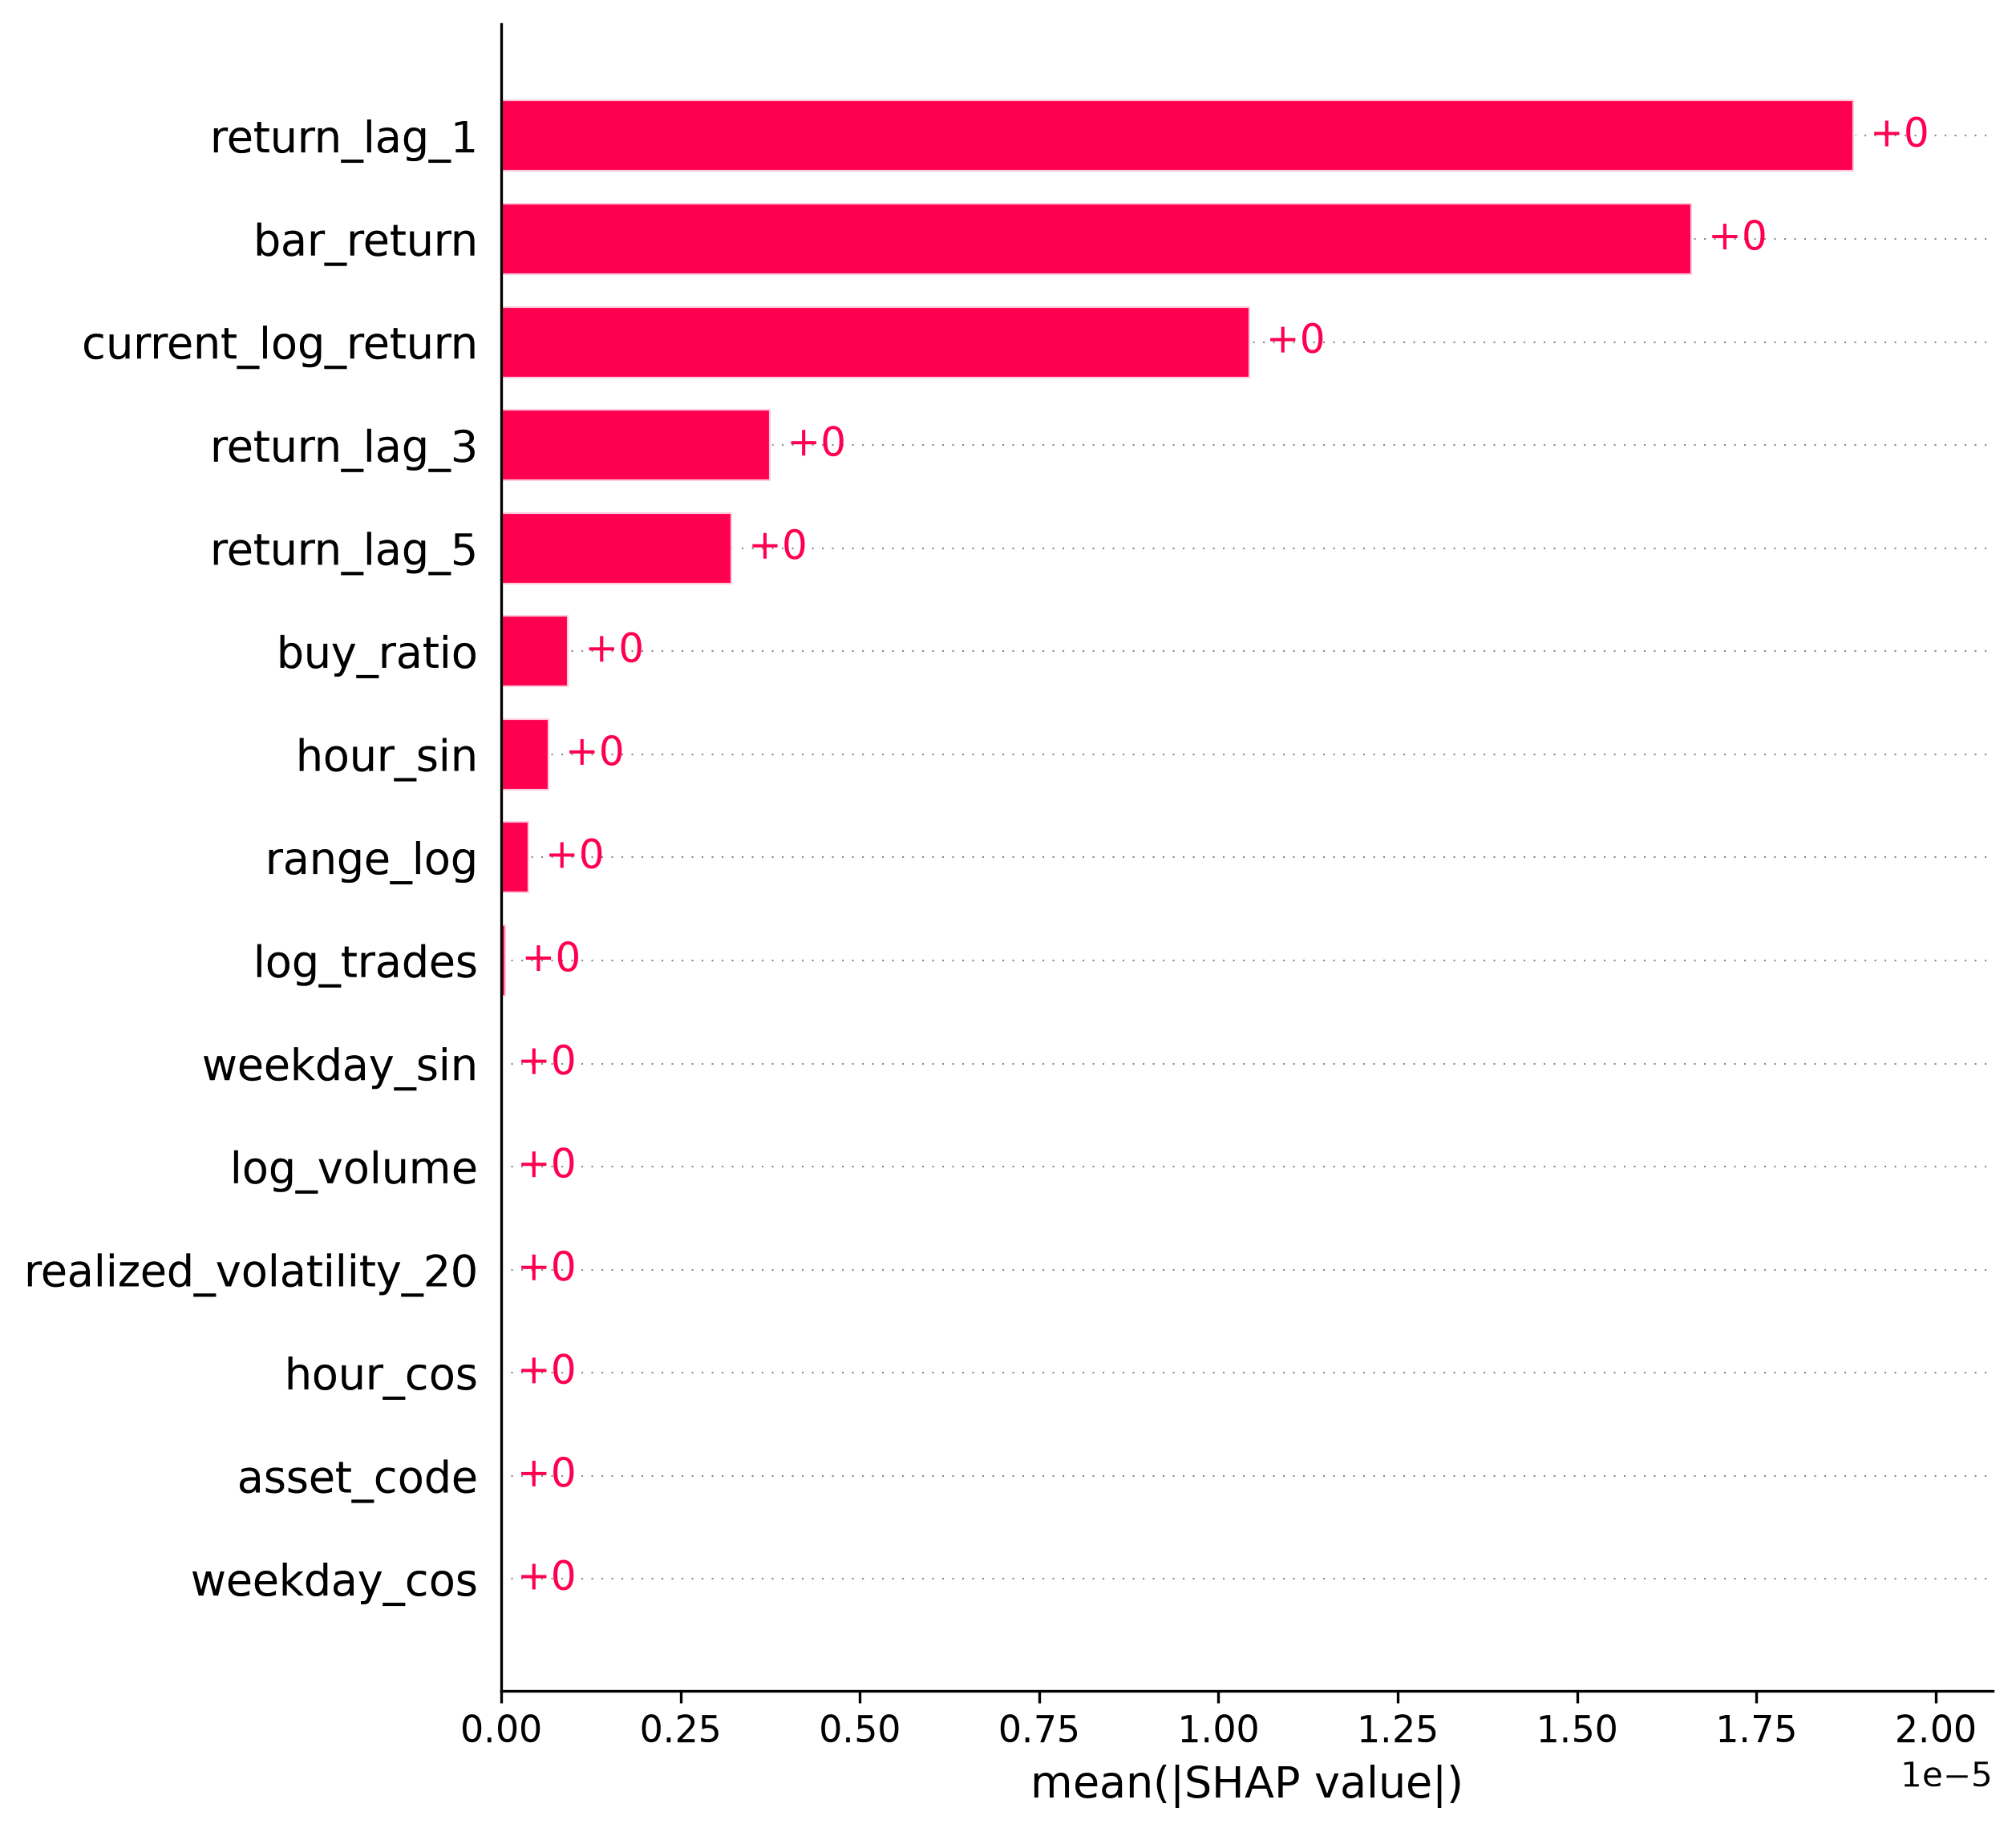

shap_waterfall.png


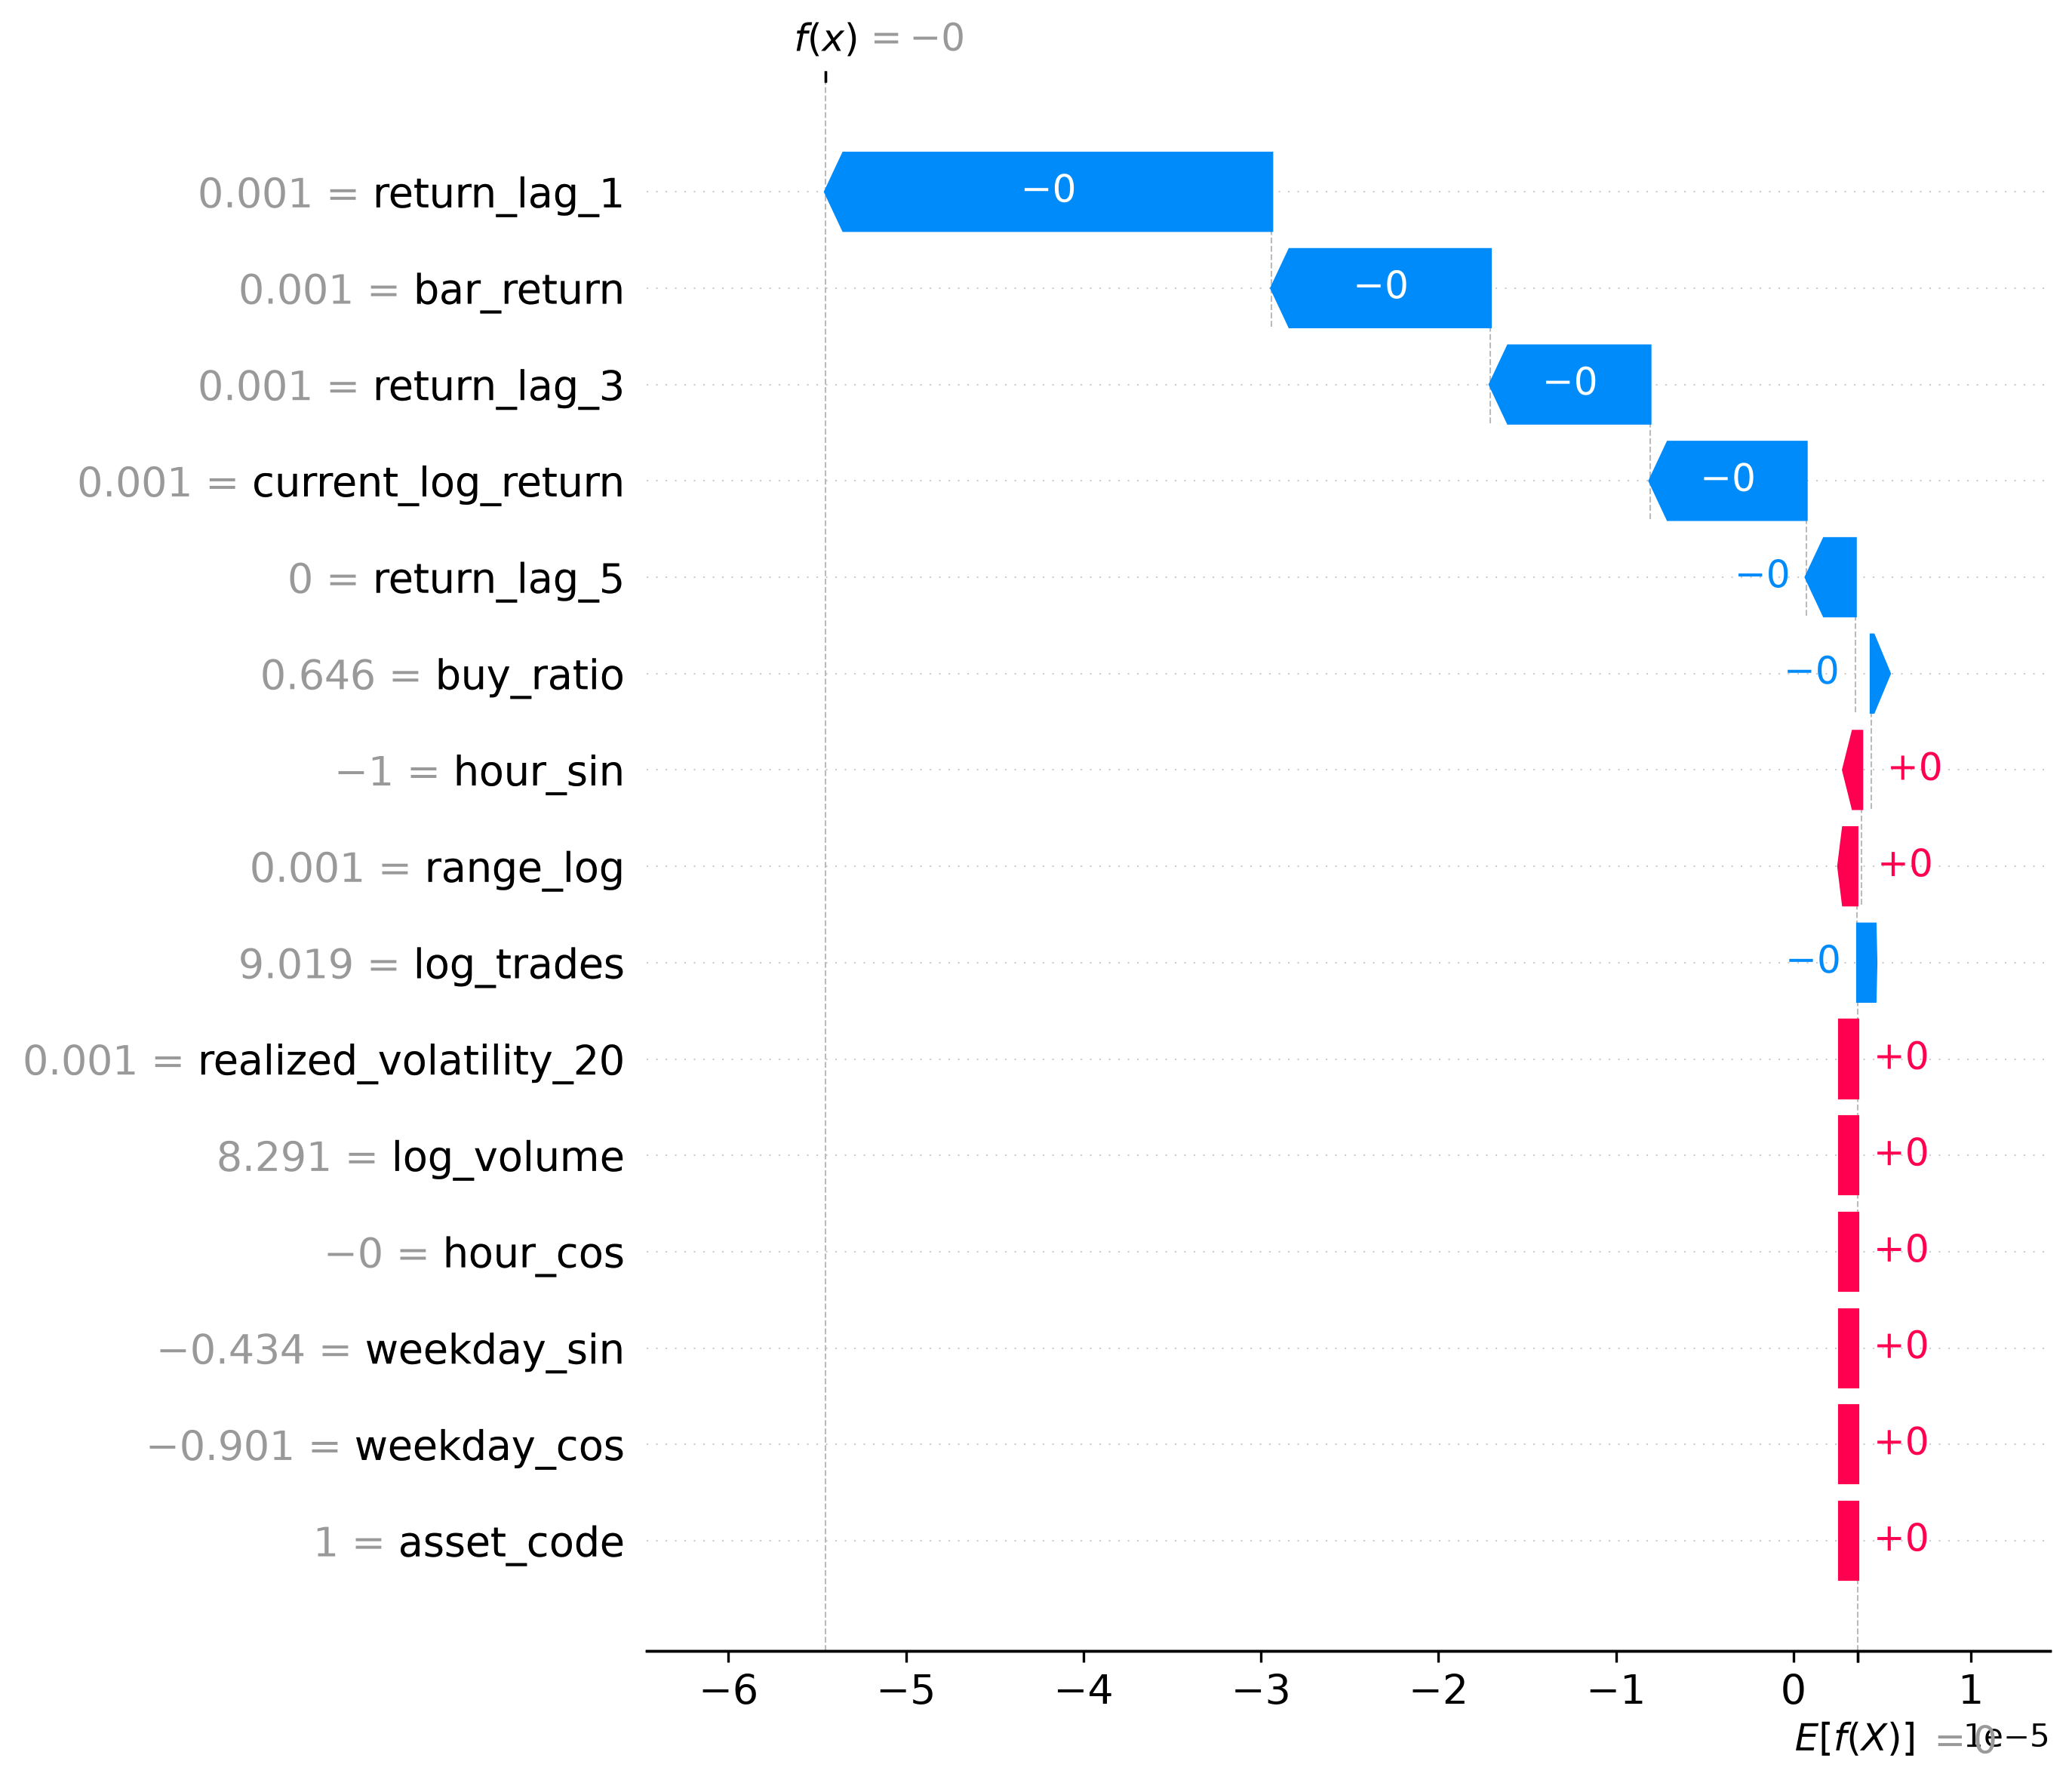

Best parameters: {'max_iter': 40, 'learning_rate': 0.027384761347597136, 'max_leaf_nodes': 15, 'l2_regularization': 0.679657809075816}


In [15]:
for figure_name in [
    'residual_diagnostics.png',
    'shap_summary.png',
    'shap_importance_bar.png',
    'shap_waterfall.png',
]:
    print(figure_name)
    display(Image(filename=str(FIGURES_DIR / figure_name)))
print('Best parameters:', best_row['best_parameters'])

<a id="chapter-8"></a>
# 8. Strategic Conclusions & Future Recommendations

The final decision should depend on out-of-time stability, not one pooled score. Before any strategy claim, test turnover, spread, fees, slippage, latency, position sizing, and robustness across regimes and assets.

In [16]:
display(leaderboard)
print('Data end:', metrics['data']['end_utc'])
print('OOF rows per model:', metrics['data']['oof_rows_per_model'])
print('Model artifact:', ROOT / 'models' / 'best_model.joblib')
print('Training did not model fees, slippage, or execution.')

,model,OOF MAE,OOF MAE skill vs zero,OOF RMSE,OOF rank IC,Holdout MAE,Holdout MAE skill vs zero,Holdout RMSE,Holdout rank IC
1,HistGradientBoostingRegressor,0.000919,0.000942,0.001454,0.033866,0.000826,0.001831,0.001331,0.049364
2,LGBMRegressor,0.000919,0.000921,0.001455,0.034278,0.000825,0.002381,0.001333,0.050346
3,CatBoostRegressor,0.000919,0.000843,0.001454,0.032916,0.000826,0.001555,0.001331,0.049679
0,Ridge,0.000919,0.000403,0.001454,0.023036,0.000826,0.001160,0.001332,0.038518


Data end: 2026-07-26T17:24:00+00:00
OOF rows per model: 651360
Model artifact: D:\File VS Code\kaw\models\best_model.joblib
Training did not model fees, slippage, or execution.
